# 02 · Train

Trains on the dataset from `01_download_dataset.ipynb`; runs go to `runs/`.

- `MODEL = "yolo"` (default): Ultralytics **YOLO26-seg**, size `x` (most accurate). AGPL-3.0.
- `MODEL = "rfdetr"`: **RF-DETR-Seg**. Apache 2.0.

In [1]:
import os
from pathlib import Path

import torch
from dotenv import load_dotenv

ROOT = Path.cwd()
load_dotenv(ROOT / ".env")

DATA_VERSION = f"v{os.environ['ROBOFLOW_VERSION']}"
DATA_NAME = f"{os.environ['ROBOFLOW_PROJECT']}-{DATA_VERSION}"  # e.g. leaf-dis-seg-v1
DATASET_DIR = ROOT / "datasets" / f"{DATA_NAME}-coco"
YOLO_DATA = ROOT / "datasets" / f"{DATA_NAME}-yolo" / "data.yaml"

print("data:", DATA_NAME)
print("torch", torch.__version__, "| CUDA:", torch.cuda.is_available(), torch.cuda.get_device_name(0) if torch.cuda.is_available() else "")

data: lds_v1-v2
torch 2.11.0+cu128 | CUDA: True NVIDIA RTX PRO 5000 Blackwell


## Settings

**Before running: restart the kernel** (Kernel → Restart) and check the printout of this cell. An old version of this notebook still open in the editor once trained with the wrong settings.

- **Run name** = model + dataset + `RUN_TAG`, e.g. `yolo26x-seg_lds_v2-v1_ft`, so runs on different projects and versions never share a folder.
- **Resuming is automatic.** No checkpoint in the run folder → new run. Unfinished `weights/last.pt` (or `checkpoint.pth` for RF-DETR) → resume with the original settings. Finished → nothing to do; set a new `RUN_TAG` for another run.
- `INIT`: where a new YOLO run starts.
  - `"coco"`: Ultralytics' COCO-pretrained `yolo26{YOLO_SIZE}-seg.pt`.
  - `"checkpoint"`: fine-tune `INIT_CHECKPOINT` (e.g. the current best model) with a lower learning rate `LR0`. Cheaper than starting over when the model already knows this data.
- `OVERLAP_MASK = False`: each mask is learned whole. The Ultralytics default (`True`) merges an image's masks, so lesions punch holes in their leaf and the model predicts leaves with holes.
- YOLO augmentation is light because the Roboflow data is already augmented:
  - hue off, saturation and brightness reduced, because colour is what tells mildew (white), spots (brown) and leaf (green) apart;
  - vertical flips on, since leaves have no "up";
  - `copy_paste` pastes lesions between images;
  - `erasing` off, because random erasing hides small lesions.
- `SAVE_PERIOD`: keep the weights every N epochs (`weights/epoch5.pt`, …), so `10_checkpoint_select.ipynb` can pick the epoch with the most accurate coverage.
- `BATCH`: lower it if you run out of GPU memory. `x` at 1024 needs about 24 GB at batch 8; at `IMGSZ = 1280`, use batch 4.
- RF-DETR: `RFDETR_SIZE` `Nano` … `2XLarge`; effective batch = `BATCH_SIZE × GRAD_ACCUM` (aim for 16).

In [ ]:
MODEL = "yolo"  # "yolo" or "rfdetr"
RUN_TAG = "_ft"  # names this run; change it to start a separate run

# YOLO
YOLO_SIZE = "x"
INIT = "checkpoint"  # "coco" (start from COCO weights) or "checkpoint" (fine-tune INIT_CHECKPOINT)
INIT_CHECKPOINT = ROOT / "runs" / "yolo26x-seg_data-v2" / "weights" / "best.pt"
LR0 = 0.002  # initial learning rate; used for fine-tuning (COCO runs use the Ultralytics default)
EPOCHS = 100
IMGSZ = 1024
BATCH = 8
PATIENCE = 40  # stop early after this many epochs without improvement
SAVE_PERIOD = 5  # keep the weights every N epochs (for 10_checkpoint_select)
OVERLAP_MASK = False
YOLO_AUG = dict(
    hsv_h=0.0, hsv_s=0.2, hsv_v=0.2,
    degrees=10, translate=0.1, scale=0.3, shear=0.0,
    fliplr=0.5, flipud=0.5,
    mosaic=1.0, close_mosaic=10, copy_paste=0.2, mixup=0.0, erasing=0.0,
)

# RF-DETR
RFDETR_SIZE = "Medium"
RESOLUTION = None
RFDETR_EPOCHS = 50
BATCH_SIZE = 4
GRAD_ACCUM = 4
LR = 1e-4

MODEL_NAME = f"yolo26{YOLO_SIZE}-seg" if MODEL == "yolo" else f"rfdetr-seg-{RFDETR_SIZE.lower()}-{RESOLUTION or 'default'}"
RUN_NAME = f"{MODEL_NAME}_{DATA_NAME}{RUN_TAG}"
RUN_DIR = ROOT / "runs" / RUN_NAME
LAST_CHECKPOINT = RUN_DIR / ("weights/last.pt" if MODEL == "yolo" else "checkpoint.pth")
if MODEL == "yolo" and INIT == "checkpoint":
    assert INIT_CHECKPOINT.exists(), f"{INIT_CHECKPOINT} not found"

# Decide what to do from the run folder: "new", "resume" or "finished"
if not LAST_CHECKPOINT.exists():
    ACTION = "new"
elif MODEL == "yolo":
    ckpt = torch.load(LAST_CHECKPOINT, map_location="cpu", weights_only=False)
    # Ultralytics strips the optimizer from last.pt when a run ends (all epochs or early stopping)
    ACTION = "finished" if ckpt.get("optimizer") is None else "resume"
    if ACTION == "resume":
        print(f"last saved epoch: {ckpt['epoch'] + 1} of {ckpt['train_args']['epochs']} "
              f"(resuming keeps the settings the run started with)")
    del ckpt
else:
    ACTION = "resume"

print(f"{MODEL} {ACTION} → {RUN_DIR}")
print(f"data {YOLO_DATA.relative_to(ROOT)} | start {INIT_CHECKPOINT.relative_to(ROOT) if INIT == 'checkpoint' else 'COCO'} | "
      f"epochs {EPOCHS} patience {PATIENCE} imgsz {IMGSZ} batch {BATCH}" + (f" lr0 {LR0}" if INIT == "checkpoint" else ""))
print(f"overlap_mask {OVERLAP_MASK} | augmentation {YOLO_AUG}")

## Train

`workers=0` loads data in the notebook process; Windows multiprocessing data loaders often hang inside Jupyter. Raise it if training is data-bound.

When resuming, YOLO reloads every setting (data, epochs, image size, batch, augmentation, workers) from the checkpoint, so the run continues exactly as it was started. If training is interrupted (kernel restart, crash, PC shutdown), just run this notebook again.

In [ ]:
if ACTION == "finished":
    print("This run already finished; nothing to train. Change RUN_TAG for a new run.")
elif MODEL == "yolo":
    from ultralytics import YOLO

    if ACTION == "resume":
        YOLO(LAST_CHECKPOINT).train(resume=True)
    else:
        model = YOLO(INIT_CHECKPOINT if INIT == "checkpoint" else f"yolo26{YOLO_SIZE}-seg.pt")
        model.train(
            data=str(YOLO_DATA),
            epochs=EPOCHS,
            imgsz=IMGSZ,
            batch=BATCH,
            patience=PATIENCE,
            save_period=SAVE_PERIOD,
            overlap_mask=OVERLAP_MASK,
            **({"lr0": LR0} if INIT == "checkpoint" else {}),
            project=str(ROOT / "runs"),
            name=RUN_NAME,
            exist_ok=True,  # safe: a new run only starts when the folder has no checkpoint
            device=0,
            workers=0,
            **YOLO_AUG,
        )
else:
    import rfdetr

    model = getattr(rfdetr, f"RFDETRSeg{RFDETR_SIZE}")(**({"resolution": RESOLUTION} if RESOLUTION else {}))
    model.train(
        dataset_dir=str(DATASET_DIR),
        epochs=RFDETR_EPOCHS,
        batch_size=BATCH_SIZE,
        grad_accum_steps=GRAD_ACCUM,
        lr=LR,
        output_dir=str(RUN_DIR),
        early_stopping=True,
        **({"resume": str(LAST_CHECKPOINT)} if ACTION == "resume" else {}),
    )

In [ ]:
# Check: the settings the run actually used (read back from the checkpoint), against this notebook's settings
if MODEL == "yolo" and LAST_CHECKPOINT.exists():
    used = torch.load(LAST_CHECKPOINT, map_location="cpu", weights_only=False)["train_args"]
    expected = {"data": str(YOLO_DATA), "imgsz": IMGSZ, "overlap_mask": OVERLAP_MASK, **YOLO_AUG,
                **({"lr0": LR0} if INIT == "checkpoint" else {})}
    wrong = {k: (used.get(k), v) for k, v in expected.items() if str(used.get(k)) != str(v)}
    print("start weights:", used.get("model"))
    print("all settings as planned" if not wrong else f"DIFFERENT from this notebook (used, planned): {wrong}")

## Outputs

Best checkpoint for `03_evaluate.ipynb` and `04_export.ipynb`:
- YOLO: `runs/<run>/weights/best.pt` (training curves: `results.png`)
- RF-DETR: `runs/<run>/checkpoint_best_total.pth`

In [4]:
for f in sorted(RUN_DIR.rglob("*")):
    if f.is_file():
        print(f"{f.stat().st_size / 1e6:8.1f} MB  {f.relative_to(RUN_DIR)}")

     0.0 MB  args.yaml
     0.2 MB  BoxF1_curve.png
     0.2 MB  BoxP_curve.png
     0.2 MB  BoxPR_curve.png
     0.2 MB  BoxR_curve.png
     0.1 MB  confusion_matrix.png
     0.1 MB  confusion_matrix_normalized.png
     0.1 MB  labels.jpg
     0.2 MB  MaskF1_curve.png
     0.2 MB  MaskP_curve.png
     0.2 MB  MaskPR_curve.png
     0.2 MB  MaskR_curve.png
     0.0 MB  results.csv
     0.5 MB  results.png
     0.6 MB  train_batch0.jpg
     0.6 MB  train_batch1.jpg
     0.6 MB  train_batch2.jpg
     1.0 MB  val_batch0_labels.jpg
     1.0 MB  val_batch0_pred.jpg
     0.9 MB  val_batch1_labels.jpg
     1.0 MB  val_batch1_pred.jpg
     1.0 MB  val_batch2_labels.jpg
     1.0 MB  val_batch2_pred.jpg
   141.8 MB  weights\best.pt
   706.3 MB  weights\epoch0.pt
   706.3 MB  weights\epoch10.pt
   706.3 MB  weights\epoch20.pt
   706.3 MB  weights\epoch30.pt
   706.3 MB  weights\epoch40.pt
   706.3 MB  weights\epoch50.pt
   706.3 MB  weights\epoch60.pt
   706.3 MB  weights\epoch70.pt
   706.3 MB  w

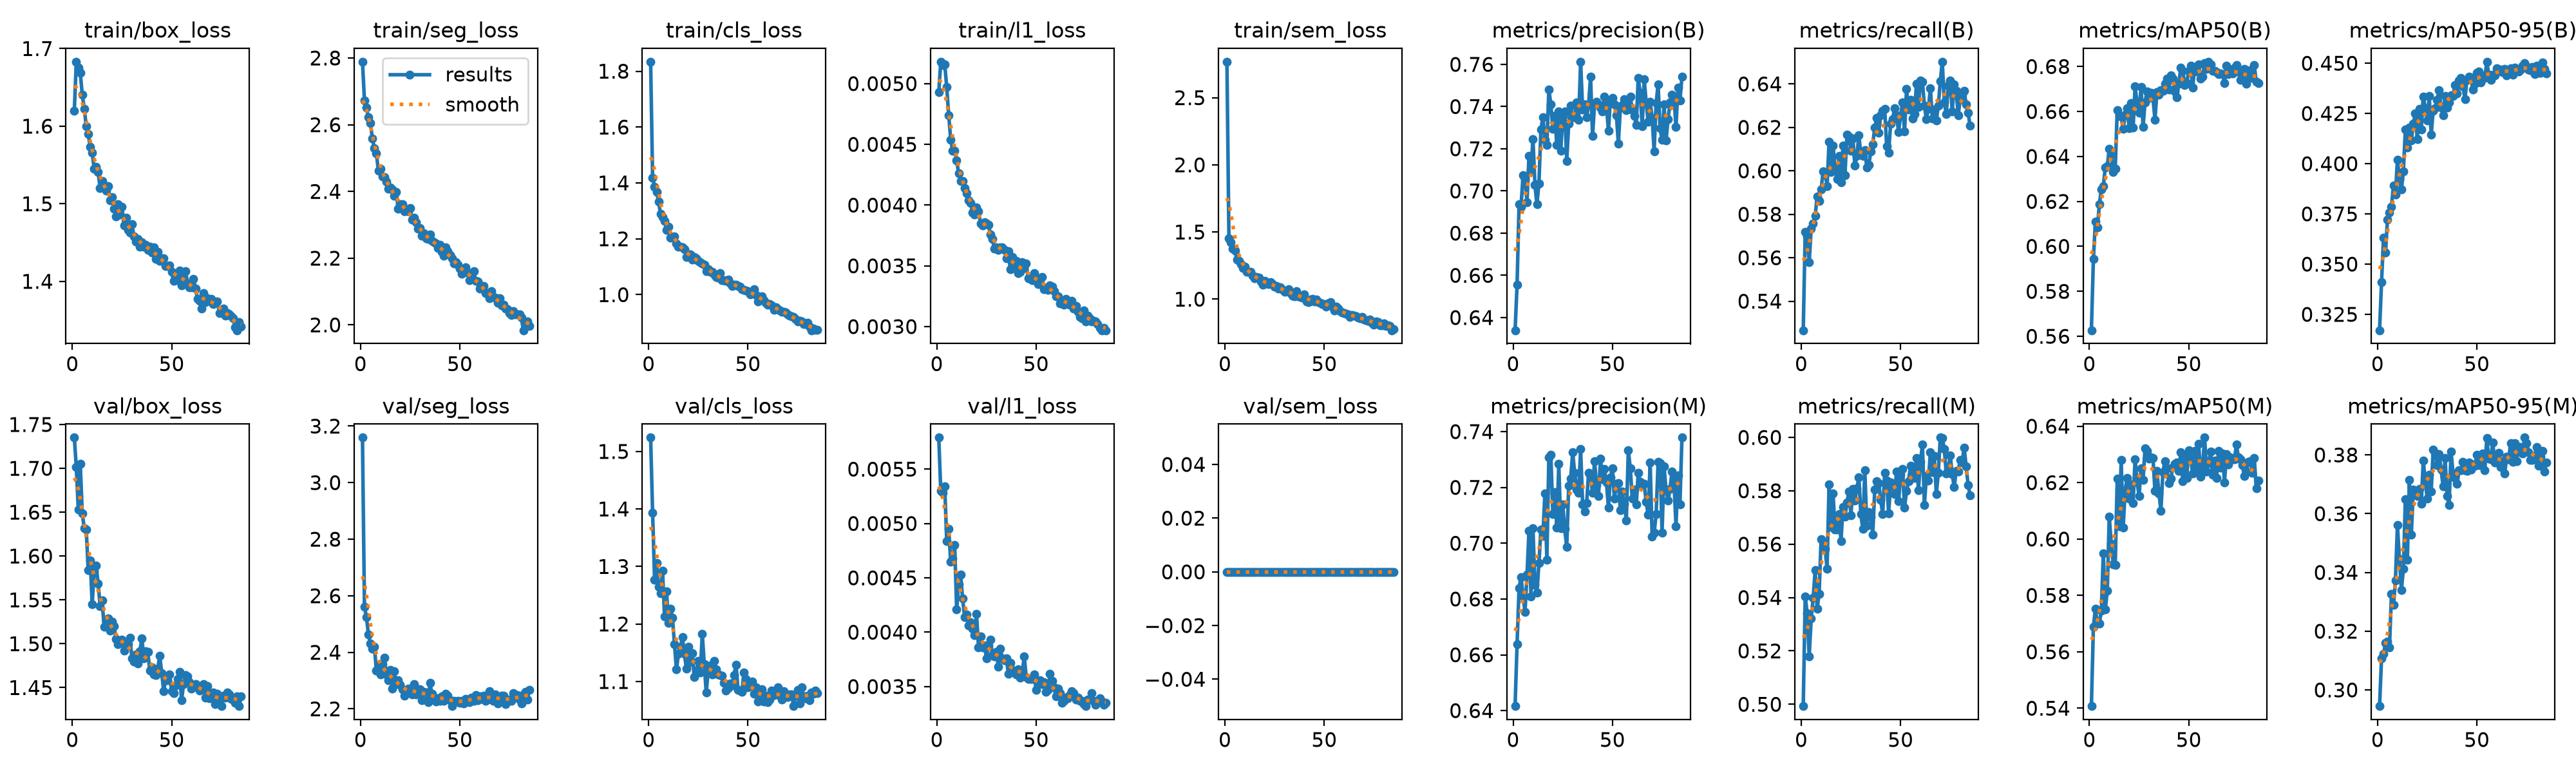

In [5]:
from IPython.display import Image as Show

if (RUN_DIR / "results.png").exists():
    display(Show(filename=RUN_DIR / "results.png"))